# Hospital Segmentation Study
**Hyderabad community-clinic network: who should we focus on, and what should we do for each group?**

> **Data note.** The brief refers to anonymised records of a fictional network but no files were supplied, so the data used here are **simulated** by `generate_data.py` (seeded, reproducible). The simulator deliberately reproduces the three defects named in the brief (free-text diagnosis, age as integer *or* date of birth, GST counted twice) plus a few usual extras (duplicates, refunds, keying errors). All figures below describe this simulated network, and all costs/benefits are planning assumptions in INR, not measured facts.

**Entity segmented:** the patient (active in a 12-month window). Doctor / department mix is shown per segment as a secondary view.

**Method in one paragraph.** Clean -> engineer frequency / recency / value / growth / seasonality features -> inspect skew and outliers -> segment two ways (RFM scoring, k-means on scaled features with k chosen by elbow + silhouette) -> profile each segment on KPIs that were **not** used to build it (length of stay, bed-days / occupancy, 30-day readmission) -> pick the better segmentation -> action plan with cost / benefit -> test stability on two different years.

| Section | Content |
|---|---|
| 1 | Load, audit and clean |
| 2 | Feature engineering |
| 3 | Distributions, skew, outliers |
| 4 | RFM segmentation |
| 5 | k-means: elbow and silhouette |
| 6 | Profile of the k-means segments (named) |
| 7 | RFM vs k-means: which one and why |
| 8 | Actions, costs and measurable targets |
| 9 | Stability and migration (2024 vs 2025) |
| 10 | Appendix: check against the simulator's hidden truth |

In [1]:
import warnings, os, re
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.patches import Polygon
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from prep import load_and_clean, build_events, features, parse_age, map_diagnosis
import seg
from seg import (model_matrix, scaled, rfm, k_sweep, fit_km, outcomes, profile, kpi_separation,
                 match_labels, change_rate, KM_FEATS)

pd.set_option("display.width", 220, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.2f}")
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]   # categorical, fixed order
GREY, INK, MUTE = "#9a9a95", "#222", "#6b6b66"
mpl.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bbb",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "figure.dpi": 110, "savefig.dpi": 200,
                     "axes.grid": True, "grid.color": "#e8e8e4", "grid.linewidth": .7, "axes.axisbelow": True})
os.makedirs("outputs", exist_ok=True)
P1, P2 = ("2024-01-01", "2024-12-31"), ("2025-01-01", "2025-12-31")
RUPEE = "\u20b9"

## 1. Load, audit and clean

In [2]:
D = load_and_clean("data")
print(f"opd {len(D['opd']):,} | admissions {len(D['adm']):,} | lab tests {len(D['lab']):,} | bills {len(D['bill']):,}  (after cleaning)")
D["log"]

opd 196,129 | admissions 10,157 | lab tests 94,567 | bills 206,754  (after cleaning)


,step,issue,rows_affected,action
0,raw,total transactional rows (opd+admissions+labs+...,509602,n/a
1,patients,age entered as date of birth (mixed formats),4855,"parsed 4 date formats, converted to age at 31-..."
2,patients,"age text with suffix ('34 yrs', '34Y')",1882,stripped suffix
3,patients,unparseable / impossible age,0,set to median age
4,opd,exact duplicate visit rows,784,dropped
5,opd,duplicate visit_id after exact-dup removal,0,dropped
6,opd,missing doctor_id,1946,set to UNKNOWN (kept; doctor not used for segm...
7,admissions,duplicate admission_id,0,dropped
8,admissions,discharge date before admission date,6,dropped (cannot recover true LOS)
9,admissions,missing doctor_id,91,set to UNKNOWN


**Decisions worth knowing**

* **Age.** About 20% of rows hold a date of birth in one of four formats. They are parsed with explicit patterns (never `dayfirst` guessing), two-digit years are pivoted so a "30" means 1930, and everything becomes age in years at 31-Dec-2025.
* **Diagnosis.** Free text is mapped to 16 canonical groups by ordered regex rules, with a typo-tolerant (`difflib`) fallback on keywords. What cannot be mapped is labelled `unknown` rather than guessed. Coverage is shown below.
* **GST.** Rows where `total = base + 2 x GST` are flagged as double-counted. **Revenue is measured on the ex-GST base amount**, so the error cannot leak into any value feature (and GST is not clinic income anyway). Hospital H4 is affected on almost every bill, which points to a billing-system setting, not random keying.
* **Refunds** are netted against the original bill. **Zero-value bills** stay (the visit happened). **~100x amounts** are divided by 100 when the result lands inside the normal range; the rule is a statistical one, so a few genuine very large bills may be touched (see the log for the count).

In [3]:
cov = D["dxcov"]; print((100*cov/cov.sum()).round(1).rename("% of diagnosis entries"))
b = D["bill"]; print("\nShare of bills with GST double-counted, by hospital:")
print((100*b.groupby("hospital_id").gst_double_counted.mean()).round(1).to_string())
print("\nBilled total before vs after the GST fix (", RUPEE, "crore ):", round(b.total_amount.clip(lower=0).sum()/1e7,2), "->", round(b.total_fixed.clip(lower=0).sum()/1e7,2))

dx_method
regex      94.40
blank       3.00
fuzzy       1.50
unmapped    1.10
Name: % of diagnosis entries, dtype: float64

Share of bills with GST double-counted, by hospital:
hospital_id
H1    2.00
H2    1.90
H3    2.00
H4   99.40

Billed total before vs after the GST fix ( ₹ crore ): 97.58 -> 94.49


## 2. Feature engineering (per patient, 12-month window)

| Feature | Definition |
|---|---|
| **Frequency** | OPD visits, admissions, lab tests in the window |
| **Recency** | days from the last encounter to the end of the window |
| **Value** | ex-GST revenue (net of refunds) |
| **Growth** | (H2 - H1) / (H1 + H2 + 2): encounters in the second vs first half of the year, shrunk toward 0 so a patient with 1 visit is not "+100% growth" |
| **Seasonality** | monsoon share (Jun-Sep) of encounters, shrunk toward the calendar share of 1/3: `(m + 1/3) / (n + 1)` |
| Also | age, share of OPD visits for chronic conditions, labs per visit |

**Clinical KPIs (LOS, bed-days, 30-day readmission) are deliberately *not* clustering inputs.** They are what the segments must explain, so using them to build segments would make the "differences" circular.

**Honest caveat.** The admission *count* is an input, and bed-days and 30-day readmission are mechanically linked to it (a readmission needs two admissions in the window, so such patients land in the inpatient segments almost by construction). These KPIs therefore show that the segments are operationally meaningful, but they are not fully independent proof. Average LOS is the cleanest outcome check, because it does not depend on how many admissions a patient had.

In [4]:
ev = build_events(D)
f1 = features(D, ev, *P1); f2 = features(D, ev, *P2)
print("active patients  2024:", f"{len(f1):,}", " 2025:", f"{len(f2):,}", " active in both:", f"{len(f1.index.intersection(f2.index)):,}")
f2.describe(percentiles=[.5,.9,.99]).T[["mean","50%","90%","99%","max"]]

active patients  2024: 20,025  2025: 19,009  active in both: 15,872


,mean,50%,90%,99%,max
opd_n,4.98,3.00,12.00,24.00,47.00
adm_n,0.27,0.00,1.00,3.00,10.00
revenue,"22,037.31","4,250.90","49,397.04","291,452.27","947,101.78"
enc_n,5.25,3.00,12.00,24.00,47.00
lab_n,2.43,1.00,7.00,16.00,34.00
recency,100.67,82.00,246.00,359.00,364.00
growth,0.07,0.14,0.60,0.81,0.94
monsoon_share,0.39,0.35,0.67,0.87,0.95
chronic_share,0.30,0.00,1.00,1.00,1.00
labs_per_visit,0.37,0.30,1.00,1.75,4.00


## 3. Distributions, skew and outliers

                skew_raw  skew_after_winsor+log  IQR_outliers_%
opd_n               2.12                   0.42            4.13
lab_n               2.34                   0.64            9.50
adm_n               3.80                   2.36           16.97
recency             1.03                  -0.82            2.28
revenue             5.49                   0.38           13.18
labs_per_visit      1.38                   0.61            1.17


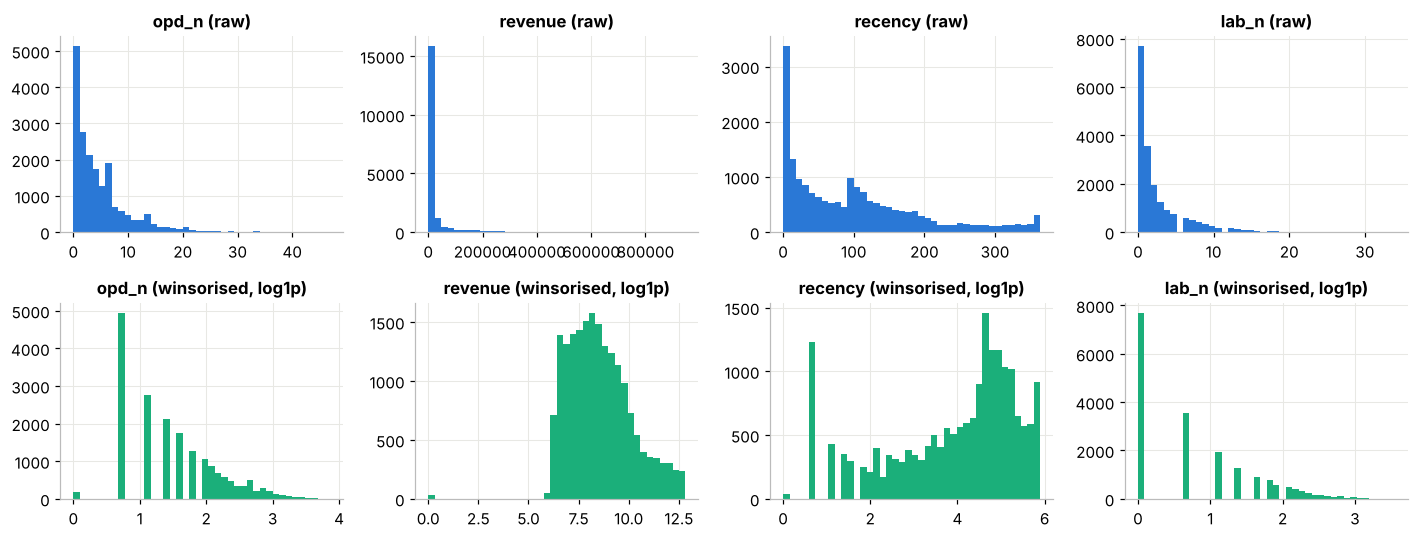

In [5]:
cols = ["opd_n","lab_n","adm_n","recency","revenue","labs_per_visit"]
X = model_matrix(f2)
sk = pd.DataFrame({"skew_raw": f2[cols].skew(), "skew_after_winsor+log": X[cols].skew(),
                   "IQR_outliers_%": [100*((f2[c] > f2[c].quantile(.75)+1.5*(f2[c].quantile(.75)-f2[c].quantile(.25)))).mean() for c in cols]})
print(sk)
fig, ax = plt.subplots(2, 4, figsize=(13, 5))
for i, c in enumerate(["opd_n","revenue","recency","lab_n"]):
    ax[0,i].hist(f2[c], bins=40, color=PAL[0]); ax[0,i].set_title(c + " (raw)")
    ax[1,i].hist(X[c], bins=40, color=PAL[2]); ax[1,i].set_title(c + " (winsorised, log1p)")
plt.tight_layout(); plt.show()

Counts, revenue and recency are strongly right-skewed. Outliers are handled in two steps: revenue is **winsorised at the 99.5th percentile** (a few very large inpatient bills would otherwise pull a centroid), then count / money / recency features are **log1p-transformed**. Zeros are legitimate (no admissions, no labs) so `log1p`, not `log`. Admissions stay skewed after the transform (skew 2.4) because 94% of patients have none; that zero-inflation is the real signal that separates the inpatient groups, so it is kept. Nothing is deleted: a high-spend patient is a real patient and exactly the kind of person the study is about.

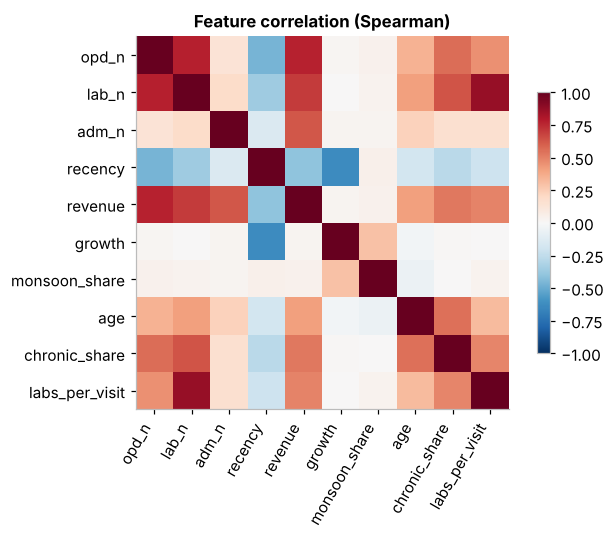

In [6]:
plt.figure(figsize=(6.5, 5)); cm = f2[KM_FEATS].corr(method="spearman")
plt.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1); plt.xticks(range(len(cm)), cm.columns, rotation=60, ha="right"); plt.yticks(range(len(cm)), cm.columns)
plt.grid(False); plt.colorbar(shrink=.7); plt.title("Feature correlation (Spearman)"); plt.tight_layout(); plt.show()

## 4. RFM segmentation

Each patient gets a 1-5 score on **R**ecency (recent = 5), **F**requency (encounters) and **M**onetary value (ex-GST revenue). Scores are quintiles of the *rank* (ties broken by order) so equal-sized bins exist even for tied counts. Score combinations map to named rule-based segments. A rule group that came out under 5% of patients in a first pass ("frequent, lower value") was merged into "Steady regulars".

In [7]:
r2 = rfm(f2); f2["rfm"] = r2.rfm_segment
w2 = outcomes(D, f2.rfm, *P2)
rfm_prof = profile(f2, "rfm", w2, *P2)
rfm_prof[["patients","share_patients_%","share_revenue_%","visits_per_patient","revenue_per_patient","median_recency_days","avg_LOS_days","occupancy_contrib_pp","readmit_30d_%"]]

,patients,share_patients_%,share_revenue_%,visits_per_patient,revenue_per_patient,median_recency_days,avg_LOS_days,occupancy_contrib_pp,readmit_30d_%
rfm,,,,,,,,,
R1 Champions,3899,20.51,45.75,11.56,"49,150.98",10.00,6.52,27.75,22.82
R2 High spenders,2025,10.65,25.51,7.77,"52,765.08",73.00,5.68,16.50,16.10
R3 Steady regulars,2752,14.48,2.73,4.15,"4,162.55",33.00,NaN,0.28,NaN
R4 Slipping valuable,3123,16.43,23.61,5.65,"31,672.47",145.00,5.75,14.28,16.15
R5 Recent light users,1567,8.24,0.57,1.51,"1,526.39",17.00,NaN,0.14,NaN
R6 Dormant light users,5643,29.69,1.83,1.34,"1,357.07",171.00,NaN,0.01,NaN


## 5. k-means on scaled features: elbow and silhouette

In [8]:
Xs2, Xm2 = scaled(f2)                       # winsorise -> log1p -> StandardScaler
sw = k_sweep(Xs2, range(2, 11))
# outcome-KPI separation for each k (eta-squared of LOS, bed-days, readmission)
rows = []
for k in sw.k:
    lab = pd.Series(fit_km(Xs2, k).labels_, index=f2.index)
    tmp = f2.assign(_s=lab); ws = outcomes(D, lab, *P2)
    e = kpi_separation(tmp, "_s", ws).set_index("kpi").eta_squared
    rows.append(e[["avg LOS (admitted patients)", "bed-days per patient", "30-day readmission (index stays)"]].mean())
sw["outcome_KPI_eta2"] = rows
sw

,k,inertia,silhouette,davies_bouldin,min_share,outcome_KPI_eta2
0,2,"132,968.38",0.30,1.44,0.38,0.05
1,3,"117,232.92",0.28,1.57,0.15,0.17
2,4,"104,479.47",0.20,1.80,0.14,0.18
3,5,"93,912.07",0.22,1.61,0.13,0.18
4,6,"86,875.02",0.21,1.56,0.12,0.19
5,7,"80,233.13",0.21,1.45,0.11,0.20
6,8,"75,393.09",0.22,1.48,0.07,0.22
7,9,"71,955.53",0.22,1.49,0.07,0.21
8,10,"69,106.64",0.22,1.50,0.07,0.21


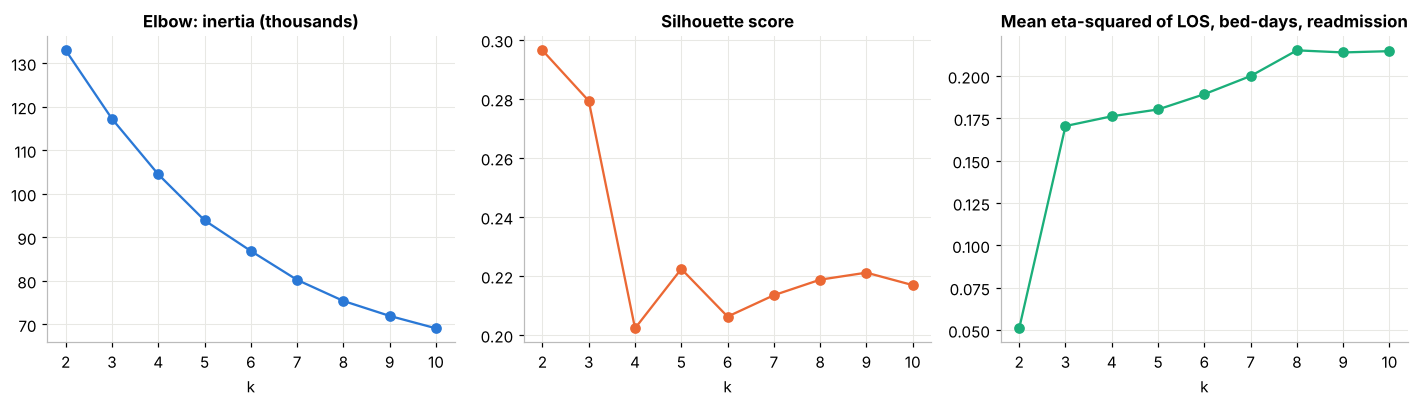

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(sw.k, sw.inertia/1e3, "-o", color=PAL[0]); ax[0].set_title("Elbow: inertia (thousands)"); ax[0].set_xlabel("k")
ax[1].plot(sw.k, sw.silhouette, "-o", color=PAL[1], label="silhouette (higher = better)")
ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
ax[2].plot(sw.k, sw.outcome_KPI_eta2, "-o", color=PAL[2]); ax[2].set_title("Mean eta-squared of LOS, bed-days, readmission"); ax[2].set_xlabel("k")
for a in ax: a.set_xticks(sw.k)
plt.tight_layout(); plt.show()

In [10]:
# Selection rule, written down before looking at the answer:
#   1) every segment >= 5% of patients;  2) k >= 4 (fewer is too coarse to act on);
#   3) smallest k whose outcome-KPI separation is within 2% of the best achievable.
ok = sw[(sw.min_share >= .05) & (sw.k >= 4)]
best = ok.outcome_KPI_eta2.max()
K = int(ok[ok.outcome_KPI_eta2 >= .98*best].k.min())
print("chosen k =", K); print(sw[sw.k == K].round(3).to_string(index=False))

chosen k = 8
 k   inertia  silhouette  davies_bouldin  min_share  outcome_KPI_eta2
 8 75,393.09        0.22            1.48       0.07              0.21


**Reading the plots.** The elbow is gentle, with no sharp kink, because behaviour in a clinic is a continuum (a patient seen 3 times is not very different from one seen 4 times). Silhouette is highest at k=2 (just "inpatient-heavy vs not"), which is too coarse to act on, and then sits on a plateau of about 0.2 for k = 4 to 10. The silhouette alone therefore cannot choose k. The tie-breaker is whether extra clusters separate **clinical KPIs that were not used for clustering**: that jumps when the big "ever admitted" group splits into a *frail, high-readmission* group and an *episodic surgical / maternity* group, and then goes flat. That is the stopping point, and it is also the largest k for which every segment stays above 5%.

In [11]:
km = fit_km(Xs2, K); f2["km_raw"] = km.labels_
w2k = outcomes(D, f2.km_raw, *P2)
praw = profile(f2, "km_raw", w2k, *P2)

def name_segment(r):
    if r.admissions_per_100 >= 100:
        return "Frail high-need inpatients" if r.mean_age >= 60 else "Surgical & maternity inpatients"
    if r.chronic_share >= .6 and r.visits_per_patient >= 8:
        return "Chronic regulars - slipping" if r.growth < 0 else "Chronic regulars - engaged"
    if r.monsoon_share >= .5:
        return "Monsoon-peak regulars" if r.visits_per_patient >= 3 else "Monsoon-peak occasionals"
    if r.median_recency_days >= 200:
        return "Lapsed light users"
    return "Recent light users"

names = praw.apply(name_segment, axis=1)
assert names.is_unique, names
f2["segment"] = f2.km_raw.map(names)
print(names.to_string())

km_raw
0              Monsoon-peak regulars
1                 Recent light users
2         Chronic regulars - engaged
3                 Lapsed light users
4    Surgical & maternity inpatients
5         Frail high-need inpatients
6        Chronic regulars - slipping
7           Monsoon-peak occasionals


## 6. Profile of the final segments

In [12]:
w2 = outcomes(D, f2.segment, *P2)
prof = profile(f2, "segment", w2, *P2).sort_values("share_revenue_%", ascending=False)
ORDER = list(prof.index); COL = dict(zip(ORDER, PAL)); COL.update({"New in 2025": GREY, "Not active in 2025": GREY})
show = ["patients","share_patients_%","share_revenue_%","share_visits_%","revenue_per_patient","visits_per_patient","admissions_per_100",
        "avg_LOS_days","share_bed_days_%","occupancy_contrib_pp","readmit_30d_%","readmit_denominator","mean_age","chronic_share","median_recency_days","growth","monsoon_share"]
prof[show]

,patients,share_patients_%,share_revenue_%,share_visits_%,revenue_per_patient,visits_per_patient,admissions_per_100,avg_LOS_days,share_bed_days_%,occupancy_contrib_pp,readmit_30d_%,readmit_denominator,mean_age,chronic_share,median_recency_days,growth,monsoon_share
segment,,,,,,,,,,,,,,,,,
Frail high-need inpatients,1359,7.15,44.14,14.30,"136,056.03",10.50,197.94,7.30,63.22,37.28,25.70,2331,67.27,0.75,27.00,0.09,0.38
Surgical & maternity inpatients,1441,7.58,31.69,6.88,"92,129.39",4.76,137.13,4.92,32.06,18.90,13.25,1759,43.64,0.11,74.00,0.08,0.40
Chronic regulars - engaged,2255,11.86,8.56,25.39,"15,892.71",11.23,6.08,4.53,1.70,1.00,0.00,83,57.37,0.80,5.00,0.43,0.37
Chronic regulars - slipping,2337,12.29,7.54,22.12,"13,507.91",9.45,4.62,3.69,1.32,0.78,0.00,108,58.12,0.81,95.00,-0.34,0.30
Monsoon-peak regulars,2710,14.26,3.21,10.98,"4,955.91",4.04,2.58,3.09,0.65,0.38,0.00,68,34.65,0.13,102.00,0.20,0.62
Recent light users,3153,16.59,2.04,8.60,"2,714.78",2.72,1.43,5.67,0.57,0.34,NaN,8,36.85,0.06,17.00,0.36,0.23
Lapsed light users,3009,15.83,1.68,6.80,"2,333.32",2.26,0.80,NaN,0.18,0.11,NaN,24,36.79,0.03,257.00,-0.39,0.19
Monsoon-peak occasionals,2745,14.44,1.15,4.93,"1,760.07",1.79,1.53,2.12,0.30,0.17,0.00,42,36.05,0.06,134.00,0.18,0.64


In [13]:
net_occ = 100*w2.bed_days.sum()/(seg.TOTAL_BEDS*365)
print(f"Network bed occupancy 2025: {net_occ:.1f}%  (140 beds).  Smallest segment: {prof['share_patients_%'].min():.1f}% of patients  (rule: >= 5%)")
print("Occupancy contribution adds up to network occupancy:", round(prof.occupancy_contrib_pp.sum(),1))

Network bed occupancy 2025: 59.0%  (140 beds).  Smallest segment: 7.1% of patients  (rule: >= 5%)
Occupancy contribution adds up to network occupancy: 59.0


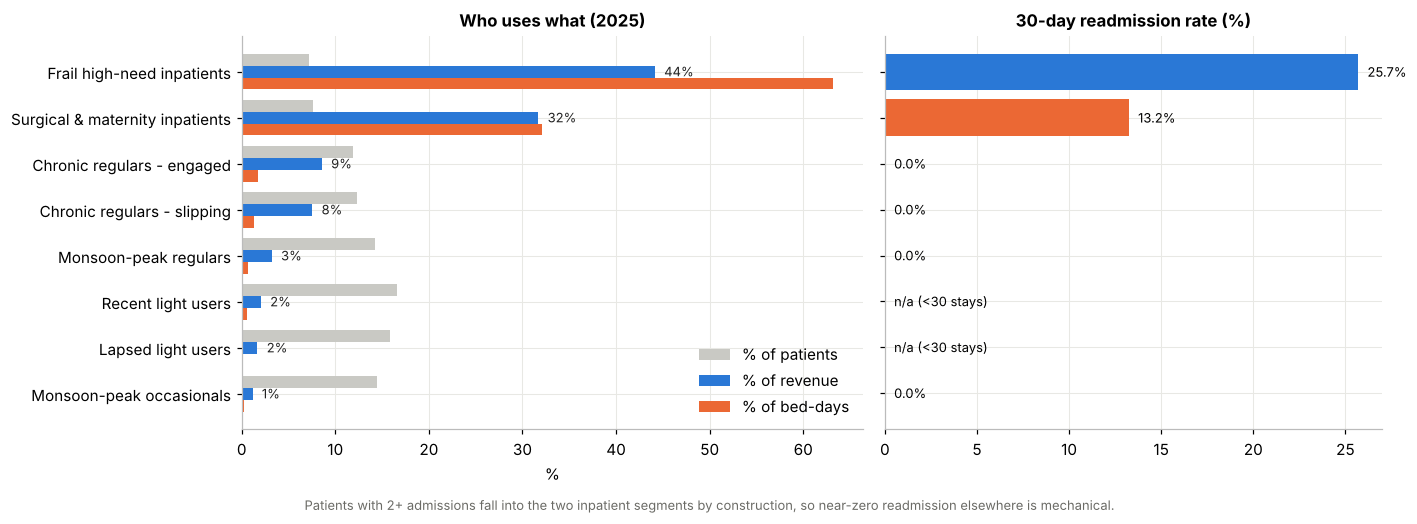

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
y = np.arange(len(ORDER))[::-1]; h = .26
ax[0].barh(y+h, prof["share_patients_%"], h, color="#c9c9c4", label="% of patients")
ax[0].barh(y,   prof["share_revenue_%"],  h, color=PAL[0], label="% of revenue")
ax[0].barh(y-h, prof["share_bed_days_%"], h, color=PAL[1], label="% of bed-days")
ax[0].set_yticks(y); ax[0].set_yticklabels(ORDER); ax[0].legend(frameon=False, loc="lower right"); ax[0].set_title("Who uses what (2025)")
ax[0].set_xlabel("%")
for yy, v in zip(y, prof["share_revenue_%"]): ax[0].text(v+1, yy, f"{v:.0f}%", va="center", fontsize=8.5, color=INK)
ax[1].barh(y, prof["readmit_30d_%"].fillna(0), color=[COL[s] for s in ORDER]); ax[1].set_yticks(y); ax[1].set_yticklabels([])
ax[1].set_title("30-day readmission rate (%)");
for yy, v in zip(y, prof["readmit_30d_%"]): ax[1].text((0 if np.isnan(v) else v)+.5, yy, "n/a (<30 stays)" if np.isnan(v) else f"{v:.1f}%", va="center", fontsize=8.5)
fig.text(.5, -.02, "Patients with 2+ admissions fall into the two inpatient segments by construction, so near-zero readmission elsewhere is mechanical.", ha="center", fontsize=8.5, color=MUTE)
plt.tight_layout(); plt.savefig("outputs/segment_profile_chart.png", bbox_inches="tight"); plt.show()

In [15]:
# Secondary view: clinical mix (diagnosis group) per segment, 2025 encounters
e = ev[(ev.date >= P2[0]) & (ev.date <= P2[1])].copy(); e["segment"] = e.patient_id.map(f2.segment)
e = e[e.segment.notna() & (e.dx != "unknown")]
g = e.groupby(["segment","dx"]).size().rename("n").reset_index()
g["pct"] = 100*g.n/g.groupby("segment").n.transform("sum")
top3 = g.sort_values(["segment","pct"], ascending=[True, False]).groupby("segment").head(3).groupby("segment").apply(
    lambda d: ", ".join(f"{a} {b:.0f}%" for a, b in zip(d.dx, d.pct)), include_groups=False)
top3.reindex(ORDER).to_frame("top 3 diagnosis groups")

,top 3 diagnosis groups
segment,
Frail high-need inpatients,"diabetes 20%, hypertension 20%, cardiac 18%"
Surgical & maternity inpatients,"surgical 16%, injury 15%, musculoskeletal 11%"
Chronic regulars - engaged,"diabetes 34%, hypertension 30%, other 9%"
Chronic regulars - slipping,"diabetes 34%, hypertension 30%, other 10%"
Monsoon-peak regulars,"fever 22%, resp_infection 20%, gastro 13%"
Recent light users,"resp_infection 19%, fever 14%, gastro 14%"
Lapsed light users,"resp_infection 19%, fever 16%, gastro 14%"
Monsoon-peak occasionals,"resp_infection 21%, fever 19%, gastro 14%"


In [16]:
# Does the segmentation separate on at least 3 KPIs?  (success criterion)
ks = kpi_separation(f2, "segment", w2)
def spread(col, minn=None):
    s = prof[col].dropna(); return s.max()/max(s.min(), 1e-9)
labm = f2.groupby("segment").lab_n.mean()
ks["max/min across segments"] = [spread("revenue_per_patient"), spread("visits_per_patient"), spread("median_recency_days"),
                                 spread("avg_LOS_days"), np.nan, np.nan, labm.max()/labm.min()]
# readmission is a rate that can legitimately be near 0: compare with a 1-point floor on the lowest rate
rr = prof["readmit_30d_%"].dropna(); ks.loc[ks.kpi == "30-day readmission (index stays)", "max/min across segments"] = rr.max()/max(rr.min(), 1.0)
ks.loc[ks.kpi == "bed-days per patient", "max/min across segments"] = spread("occupancy_contrib_pp")
ks.loc[ks.kpi == "bed-days per patient", "max/min across segments"] = spread("occupancy_contrib_pp")
ks["clearly different"] = (ks.kruskal_p < .001) & (ks["max/min across segments"] >= 1.5)
ks

,kpi,kind,eta_squared,kruskal_p,max/min across segments,clearly different
0,revenue,input to segmentation,0.47,0.00,77.30,True
1,enc_n,input to segmentation,0.48,0.00,6.27,True
2,recency,input to segmentation,0.62,0.00,51.40,True
3,avg LOS (admitted patients),outcome (not an input),0.10,0.00,3.45,True
4,bed-days per patient,outcome (not an input),0.50,0.00,352.76,True
5,30-day readmission (index stays),outcome (not an input),0.04,0.00,25.70,True
6,lab tests per patient,outcome-ish,0.52,0.00,"18,765.82",True


**Success criterion check.** Rule used: a KPI is "clearly different" if a Kruskal-Wallis test across segments gives p < 0.001 **and** the highest segment is at least 1.5x the lowest (segments with fewer than 30 stays are excluded from LOS / readmission; readmission uses a 1-point floor on the lowest rate). The three outcome KPIs (average LOS, bed-days / occupancy contribution, 30-day readmission) all pass, as do revenue, visit frequency, recency and lab use, so the segments differ clearly on far more than three KPIs. Because bed-days and readmission are tied to the admission count (see the caveat in section 2), the most convincing single check is **average LOS**: it differs 3.5-fold between segments and was not an input. Eta-squared (share of variance explained) is reported alongside so that statistical significance on 19,000 patients is not mistaken for strength.

## 7. RFM vs k-means: which one, and why

In [17]:
Xs_s = Xs2
def quality(f, col, w, Xs):
    lab = f[col].values; n = len(f)
    idx = np.random.default_rng(0).choice(n, 8000, replace=False)
    sh = f[col].value_counts(normalize=True)
    s = kpi_separation(f, col, w).set_index("kpi")
    prof_ = profile(f, col, w, *P2)
    ind = ["avg LOS (admitted patients)", "bed-days per patient", "30-day readmission (index stays)"]
    return {"segments": f[col].nunique(), "smallest segment %": 100*sh.min(),
            "silhouette (same feature space)": silhouette_score(Xs[idx], pd.factorize(lab)[0][idx]),
            "Davies-Bouldin (lower=better)": davies_bouldin_score(Xs, pd.factorize(lab)[0]),
            "eta2 LOS": s.loc[ind[0], "eta_squared"], "eta2 bed-days": s.loc[ind[1], "eta_squared"], "eta2 readmission": s.loc[ind[2], "eta_squared"],
            "eta2 revenue (input)": s.loc["revenue", "eta_squared"]}
cmp = pd.DataFrame({"RFM (rule-based)": quality(f2, "rfm", w2, Xs2), "k-means (final)": quality(f2, "segment", w2, Xs2)})
print("ARI between RFM and k-means labels:", round(adjusted_rand_score(f2.rfm, f2.segment), 3))
cmp

ARI between RFM and k-means labels: 0.236


,RFM (rule-based),k-means (final)
segments,6.00,8.00
smallest segment %,8.24,7.15
silhouette (same feature space),0.07,0.22
Davies-Bouldin (lower=better),2.97,1.48
eta2 LOS,0.02,0.10
eta2 bed-days,0.10,0.50
eta2 readmission,0.04,0.04
eta2 revenue (input),0.14,0.47


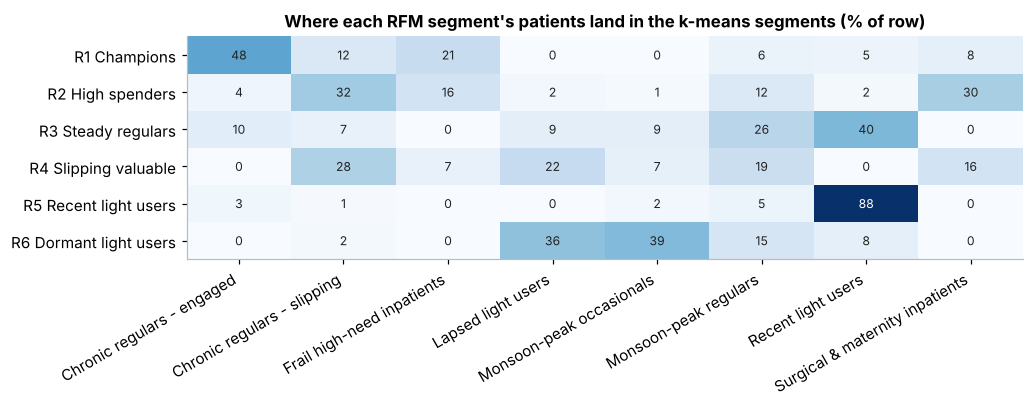

In [18]:
ct = pd.crosstab(f2.rfm, f2.segment, normalize="index")*100
fig, ax = plt.subplots(figsize=(9.5, 3.8)); im = ax.imshow(ct.values, cmap="Blues", aspect="auto"); ax.grid(False)
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=30, ha="right"); ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]): ax.text(j, i, f"{ct.values[i,j]:.0f}", ha="center", va="center", fontsize=8, color="white" if ct.values[i,j] > 50 else INK)
ax.set_title("Where each RFM segment's patients land in the k-means segments (% of row)"); plt.tight_layout(); plt.show()

**Why RFM is not enough here.** RFM sees only *how often, how recently, how much*. Those are the right questions for a shop, but a hospital's operational problems sit elsewhere: who occupies the beds, who comes back within 30 days, who is chronic. RFM's "Champions" group mixes frail inpatients with healthy-but-frequent outpatients, so one segment would need two different actions. Three of its six segments have too few admissions to quote any LOS or readmission rate at all, and its LOS / bed-day separation is weak (eta-squared 0.02 and 0.10 against 0.10 and 0.50 for k-means). On 30-day readmission neither method explains much of the variance (both 0.04: a readmission is a rare event), but k-means isolates the one group where it really bites (frail inpatients, about 26% vs 13% for surgical episodes).

**Be careful with the silhouette / Davies-Bouldin rows.** They are computed in the feature space k-means optimises, so they favour k-means by construction. The fairer tests are the outcome KPIs (eta-squared rows; the admission-count caveat applies to RFM too, since its frequency score counts admissions) plus stability and usability.

**Why k-means (k = 8) wins.** It also uses age, chronic-case share, labs per visit, growth and seasonality, so it separates patients with the same spend but different needs. On outcomes not used for clustering it clearly separates bed-days, LOS and readmission, every segment is above 5%, and each segment maps to a different operational action.

**What RFM still does better.** It is trivially explainable (a front-desk team can compute it in Excel) and its labels do not depend on a random seed. It is **not** more stable (next section), so that is not a reason to prefer it. Recommendation: **use k-means as the strategy segmentation and keep the RFM score as a simple field on each patient record** (it is in the workbook).

## 8. Actions, costs and measurable targets

**Assumptions (all INR, editable, planning-grade).** They are not measured; every effect size is the thing a pilot must confirm.

* Contribution margin on ex-GST clinic revenue: **30%**.
* Variable cost of one occupied bed-day (nursing, consumables, food): **Rs 2,000**.
* Share of 30-day readmissions that are not separately payable (package-rate / insurer rules): **50%**; only that share is counted as an avoided cost.
* Low / base / high cases scale the effect size by 0.5x / 1x / 1.5x; unit costs stay fixed.

In [19]:
MARGIN, BEDDAY, UNREIMB = .30, 2000, .5
opd_rev = e0 = ev[(ev.date >= P2[0]) & (ev.date <= P2[1]) & (ev.kind == "OPD")].copy()
opd_rev["segment"] = opd_rev.patient_id.map(f2.segment)
rev_per_visit = opd_rev.groupby("segment").rev.mean()          # ex-GST revenue per OPD visit
P = prof
def row(seg_, action, n, c1, take, c2, units, value, unit_label, target):
    cost = n*c1 + n*take*c2
    ben = n*take*units*value
    return dict(segment=seg_, action=action, patients_or_stays_reached=int(n), cost_inr=cost, benefit_base_inr=ben,
                benefit_low_inr=.5*ben, benefit_high_inr=1.5*ben, success_units=n*take*units, unit=unit_label, measurable_target=target)
A = []
s = "Frail high-need inpatients"; r = P.loc[s]; b = r["readmit_30d_%"]
A.append(row(s, "7-day post-discharge programme: nurse call for all, home visit + medication review for the highest-risk quarter",
             r.admissions, 300, b/100*.25, 0, 1, r.avg_LOS_days*BEDDAY*UNREIMB, "readmissions avoided",
             f"30-day readmission from {b:.1f}% to {b*.75:.1f}% (-25%) within 12 months; >=90% of discharges called within 7 days"))
s = "Surgical & maternity inpatients"; r = P.loc[s]
A.append(row(s, "Pre-admission checklist + discharge-planning coordinator to cut avoidable bed-days",
             r.admissions, 400, 1, 0, .5, BEDDAY, "bed-days freed",
             f"Average LOS from {r.avg_LOS_days:.1f} to {r.avg_LOS_days-.5:.1f} days (-0.5 day) with 30-day readmission not above {r['readmit_30d_%']:.1f}%"))
s = "Chronic regulars - engaged"; r = P.loc[s]
A.append(row(s, "Annual chronic-care plan (4 reviews + quarterly HbA1c / BP / lipid bundle) offered at the next visit",
             r.patients, 120, .35, 150, 2, rev_per_visit[s]*MARGIN, "extra visits",
             f"35% enrolment; +2 visits per enrolled patient per year; share of this segment with a visit in every quarter up by 15 points"))
s = "Chronic regulars - slipping"; r = P.loc[s]
A.append(row(s, "Recall at 60 days since last visit (WhatsApp + call) with a bundled check-up at a discount",
             r.patients, 90, .15, 150, 4, rev_per_visit[s]*MARGIN, "recovered visits",
             "15% of recalled patients return within 90 days (hold-out group of 10% not contacted, to measure the true lift)"))
s = "Monsoon-peak regulars"; r = P.loc[s]
A.append(row(s, "Pre-monsoon (May) fever / respiratory campaign: SMS + subsidised health check; extra doctor hours Jun-Sep",
             r.patients, 40, .20, 100, 1.5, rev_per_visit[s]*MARGIN, "extra monsoon visits",
             "20% redeem the voucher; +1.5 visits per redeemer in Jun-Sep; monsoon wait time under 30 minutes"))
s = "Monsoon-peak occasionals"; r = P.loc[s]
A.append(row(s, "Low-touch digital reminder + vaccination / health-check voucher before the monsoon",
             r.patients, 15, .08, 100, 1.0, rev_per_visit[s]*MARGIN, "extra visits",
             "8% voucher redemption; cost per redeemer under Rs 300"))
s = "Lapsed light users"; r = P.loc[s]
A.append(row(s, "Reactivation SMS with a free-consult coupon (cost incurred only if redeemed)",
             r.patients, 12, .06, 200, 1.5, rev_per_visit[s]*MARGIN, "returned visits",
             "6% return within 60 days; stop contacting non-responders after 2 messages"))
s = "Recent light users"; r = P.loc[s]
A.append(row(s, "Second-visit nudge: WhatsApp reminder + annual health-check offer to new / returning patients",
             r.patients, 15, .10, 0, 1.5, rev_per_visit[s]*MARGIN, "extra visits",
             "10% move to 3+ visits per year; share of new patients with a second visit within 90 days up by 10 points"))
act = pd.DataFrame(A)
act["net_benefit_base_inr"] = act.benefit_base_inr - act.cost_inr
act["net_low_inr"] = act.benefit_low_inr - act.cost_inr; act["net_high_inr"] = act.benefit_high_inr - act.cost_inr
act["benefit_cost_ratio_base"] = act.benefit_base_inr/act.cost_inr
act = act.set_index("segment").loc[ORDER].reset_index()
view = act[["segment","patients_or_stays_reached","cost_inr","benefit_low_inr","benefit_base_inr","benefit_high_inr","net_low_inr","net_benefit_base_inr","benefit_cost_ratio_base"]].copy()
for c in view.columns[2:8]: view[c] = (view[c]/1e5).round(2)
view.columns = ["segment","reach","cost (Rs lakh)","benefit low","benefit base","benefit high","net low","net base","benefit/cost"]
print("Totals (Rs lakh): cost", round(act.cost_inr.sum()/1e5,1), "| benefit base", round(act.benefit_base_inr.sum()/1e5,1), "| net", round(act.net_benefit_base_inr.sum()/1e5,1))
view

Totals (Rs lakh): cost 25.9 | benefit base 49.7 | net 23.7


,segment,reach,cost (Rs lakh),benefit low,benefit base,benefit high,net low,net base,benefit/cost
0,Frail high-need inpatients,2690,8.07,6.31,12.62,18.92,-1.76,4.55,1.56
1,Surgical & maternity inpatients,1976,7.90,9.88,19.76,29.64,1.98,11.86,2.50
2,Chronic regulars - engaged,2255,3.89,3.11,6.21,9.32,-0.78,2.32,1.60
3,Chronic regulars - slipping,2337,2.63,2.76,5.51,8.27,0.13,2.88,2.10
4,Monsoon-peak regulars,2710,1.63,1.39,2.78,4.17,-0.24,1.16,1.71
5,Recent light users,3153,0.47,0.69,1.39,2.08,0.22,0.92,2.94
6,Lapsed light users,3009,0.72,0.40,0.81,1.21,-0.32,0.09,1.12
7,Monsoon-peak occasionals,2745,0.63,0.30,0.60,0.90,-0.33,-0.03,0.95


In [20]:
pd.set_option("display.max_colwidth", 200)
act[["segment","action","measurable_target"]]

,segment,action,measurable_target
0,Frail high-need inpatients,"7-day post-discharge programme: nurse call for all, home visit + medication review for the highest-risk quarter",30-day readmission from 25.7% to 19.3% (-25%) within 12 months; >=90% of discharges called within 7 days
1,Surgical & maternity inpatients,Pre-admission checklist + discharge-planning coordinator to cut avoidable bed-days,Average LOS from 4.9 to 4.4 days (-0.5 day) with 30-day readmission not above 13.2%
2,Chronic regulars - engaged,Annual chronic-care plan (4 reviews + quarterly HbA1c / BP / lipid bundle) offered at the next visit,35% enrolment; +2 visits per enrolled patient per year; share of this segment with a visit in every quarter up by 15 points
3,Chronic regulars - slipping,Recall at 60 days since last visit (WhatsApp + call) with a bundled check-up at a discount,"15% of recalled patients return within 90 days (hold-out group of 10% not contacted, to measure the true lift)"
4,Monsoon-peak regulars,Pre-monsoon (May) fever / respiratory campaign: SMS + subsidised health check; extra doctor hours Jun-Sep,20% redeem the voucher; +1.5 visits per redeemer in Jun-Sep; monsoon wait time under 30 minutes
5,Recent light users,Second-visit nudge: WhatsApp reminder + annual health-check offer to new / returning patients,10% move to 3+ visits per year; share of new patients with a second visit within 90 days up by 10 points
6,Lapsed light users,Reactivation SMS with a free-consult coupon (cost incurred only if redeemed),6% return within 60 days; stop contacting non-responders after 2 messages
7,Monsoon-peak occasionals,Low-touch digital reminder + vaccination / health-check voucher before the monsoon,8% voucher redemption; cost per redeemer under Rs 300


**Reading the table.** Total cost is about Rs 26 lakh against an expected benefit of about Rs 50 lakh (low case Rs 25 lakh, high case Rs 75 lakh). The two inpatient actions carry most of the money. Surgical / maternity is positive even in the *low* case; the frail-patient programme is positive in the base case but loses about Rs 1.8 lakh at the low effect (it is mainly a quality / safety investment, and its benefit counts only the unreimbursed share of avoided readmissions). "Chronic regulars - slipping" is about break-even at the low effect and "engaged" slightly negative there, both clearly positive in the base case. Of the three light-user actions, "Recent light users" is worth running, "Lapsed light users" is marginal, and "Monsoon-peak occasionals" **does not clear its cost** in the base case, so run it only as a free add-on to the monsoon-regulars message, or drop it. Every action has a measurable target and, for campaigns, a **hold-out group** so that the lift can be separated from patients who would have returned anyway. All effect sizes are assumptions to be confirmed by a 3-month pilot before scaling.

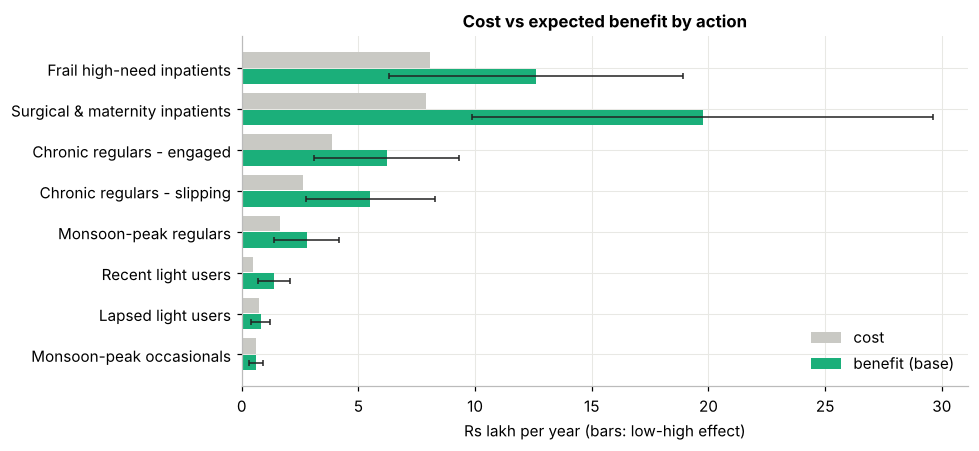

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.2)); y = np.arange(len(act))[::-1]
ax.barh(y, act.cost_inr/1e5, .38, color="#c9c9c4", label="cost")
ax.barh(y-.0, act.benefit_base_inr/1e5, .0, color="none")
ax.barh(y-.4, act.benefit_base_inr/1e5, .38, color=PAL[2], label="benefit (base)")
ax.errorbar(act.benefit_base_inr/1e5, y-.4, xerr=[(act.benefit_base_inr-act.benefit_low_inr)/1e5, (act.benefit_high_inr-act.benefit_base_inr)/1e5], fmt="none", ecolor=INK, capsize=2, lw=1)
ax.set_yticks(y-.2); ax.set_yticklabels(act.segment); ax.set_xlabel("Rs lakh per year (bars: low-high effect)"); ax.legend(frameon=False); ax.set_title("Cost vs expected benefit by action")
plt.tight_layout(); plt.savefig("outputs/action_cost_benefit.png"); plt.show()

## 9. Stability: re-running on two different periods

**Design.** (a) **Noise floor**: refit the same k-means on a random 80% of 2025 patients with a different seed, assign everyone, match segments, and count how many people change segment; any "movement" below this is just algorithm noise. (b) **Independent re-run**: fit k = 8 from scratch on 2024, match each 2024 segment to the 2025 segment with the nearest profile (Hungarian algorithm on standardised centroids), then count patients active in **both** years whose segment differs. (c) The same for RFM. Patients present in only one year are reported separately (they are lapsed or new, not "changed").

In [22]:
cols_m = ["opd_n","adm_n","lab_n","recency","revenue","growth","monsoon_share","age","chronic_share"]
# (a) noise floor
base = f2.groupby("segment")[cols_m].mean(); rng = np.random.default_rng(1); nf = []
for sd in range(5):
    idx = rng.choice(len(Xs2), int(.8*len(Xs2)), replace=False)
    k2 = KMeans(K, n_init=10, random_state=sd+10).fit(Xs2[idx]); lab = pd.Series(k2.predict(Xs2), index=f2.index)
    m, _ = match_labels(base, f2.assign(_l=lab).groupby("_l")[cols_m].mean()); nf.append(change_rate(f2.segment, lab.map(m))[0])
print("(a) noise floor, % of patients changing segment on an 80% refit:", np.round(nf, 1), " mean", round(np.mean(nf),1))

# (b) 2024 vs 2025 independent k-means
Xs1, _ = scaled(f1); km1 = fit_km(Xs1, K); f1["km_raw"] = km1.labels_
m1, dist = match_labels(f2.groupby("segment")[cols_m].mean(), f1.groupby("km_raw")[cols_m].mean())
f1["segment"] = f1.km_raw.map(m1)
print("(b) matched 2024 -> 2025 segments:", {int(k): v for k, v in m1.items()})
print("    centroid distance of each match (small = same segment recurs):", np.round(dist.min(1), 2))
both = f1.index.intersection(f2.index)
chg_km, nb = change_rate(f1.segment, f2.segment)
# (c) RFM
f1["rfm"] = rfm(f1).rfm_segment
chg_rfm, _ = change_rate(f1.rfm, f2.rfm)
# fair comparison: k-means with k=6 (same count as RFM)
Xs2_, _ = scaled(f2); Xs1_, _ = scaled(f1)
k6a, k6b = fit_km(Xs1_, 6).labels_, fit_km(Xs2_, 6).labels_
f1["k6"] = k6a; f2["k6"] = k6b
m6, _ = match_labels(f2.groupby("k6")[cols_m].mean(), f1.groupby("k6")[cols_m].mean()); chg_k6, _ = change_rate(f1.k6.map(m6), f2.k6)
stab = pd.DataFrame({"method": ["k-means k=8 (final)", "k-means k=6", "RFM (6 segments)", "noise floor (k=8 refit, same year)"],
                     "% of patients active in both years who change segment": [chg_km, chg_k6, chg_rfm, np.mean(nf)]})
print(f"\npatients active in both years: {nb:,}  | active 2024 only (lapsed): {len(f1.index.difference(f2.index)):,} | new in 2025: {len(f2.index.difference(f1.index)):,}")
stab

(a) noise floor, % of patients changing segment on an 80% refit: [0.4 0.8 0.8 0.8 0.5]  mean 0.7


(b) matched 2024 -> 2025 segments: {3: 'Chronic regulars - engaged', 6: 'Chronic regulars - slipping', 7: 'Frail high-need inpatients', 4: 'Lapsed light users', 1: 'Monsoon-peak occasionals', 0: 'Monsoon-peak regulars', 5: 'Recent light users', 2: 'Surgical & maternity inpatients'}
    centroid distance of each match (small = same segment recurs): [0.23 0.14 0.34 0.14 0.06 0.11 0.12 0.43]



patients active in both years: 15,872  | active 2024 only (lapsed): 4,153 | new in 2025: 3,137


,method,% of patients active in both years who change segment
0,k-means k=8 (final),66.41
1,k-means k=6,60.32
2,RFM (6 segments),68.61
3,"noise floor (k=8 refit, same year)",0.66


In [23]:
# retention by segment (among patients active in both years)
j = pd.concat([f1.segment.rename("y2024"), f2.segment.rename("y2025")], axis=1, join="inner")
ret = (100*(j.y2024 == j.y2025).groupby(j.y2024).mean()).reindex(ORDER).rename("% staying in same segment")
fl = pd.concat([f1.segment.rename("y2024"), f2.segment.rename("y2025")], axis=1, join="outer")
lapsed = (fl.y2025.isna() & fl.y2024.notna()).groupby(fl.y2024).mean().mul(100).reindex(ORDER).rename("% not seen in 2025")
pd.concat([ret, lapsed, f1.segment.value_counts().reindex(ORDER).rename("patients 2024")], axis=1)

,% staying in same segment,% not seen in 2025,patients 2024
Frail high-need inpatients,44.46,6.97,1291
Surgical & maternity inpatients,21.55,22.28,1773
Chronic regulars - engaged,43.72,7.54,2229
Chronic regulars - slipping,45.46,7.56,2408
Monsoon-peak regulars,29.18,19.50,2831
Recent light users,30.92,23.01,2747
Lapsed light users,31.50,36.46,4092
Monsoon-peak occasionals,22.37,24.19,2654


In [24]:
# Migration table and chart:  2024 segment -> 2025 segment, including 'New in 2025' and 'Not active in 2025'
left = f1.segment.copy(); right = f2.segment.copy()
new_ids = right.index.difference(left.index); gone_ids = left.index.difference(right.index)
mig = pd.concat([left.rename("a"), right.rename("b")], axis=1, join="outer")
mig["a"] = mig.a.fillna("New in 2025"); mig["b"] = mig.b.fillna("Not active in 2025")
flow = pd.crosstab(mig.a, mig.b).reindex(index=ORDER + ["New in 2025"], columns=ORDER + ["Not active in 2025"]).fillna(0)
flow_pct = 100*flow.div(flow.sum(axis=1), axis=0)
flow_pct.round(0).astype(int)

b,Frail high-need inpatients,Surgical & maternity inpatients,Chronic regulars - engaged,Chronic regulars - slipping,Monsoon-peak regulars,Recent light users,Lapsed light users,Monsoon-peak occasionals,Not active in 2025
a,,,,,,,,,
Frail high-need inpatients,41,8,17,18,2,2,3,2,7
Surgical & maternity inpatients,7,17,4,4,12,13,12,9,22
Chronic regulars - engaged,10,4,40,24,3,6,2,3,8
Chronic regulars - slipping,10,4,23,42,4,3,4,2,8
Monsoon-peak regulars,1,8,3,3,23,14,12,16,19
Recent light users,1,5,4,2,12,24,14,15,23
Lapsed light users,1,3,2,3,9,12,20,14,36
Monsoon-peak occasionals,1,4,2,3,17,17,16,17,24
New in 2025,3,8,6,5,16,22,21,18,0


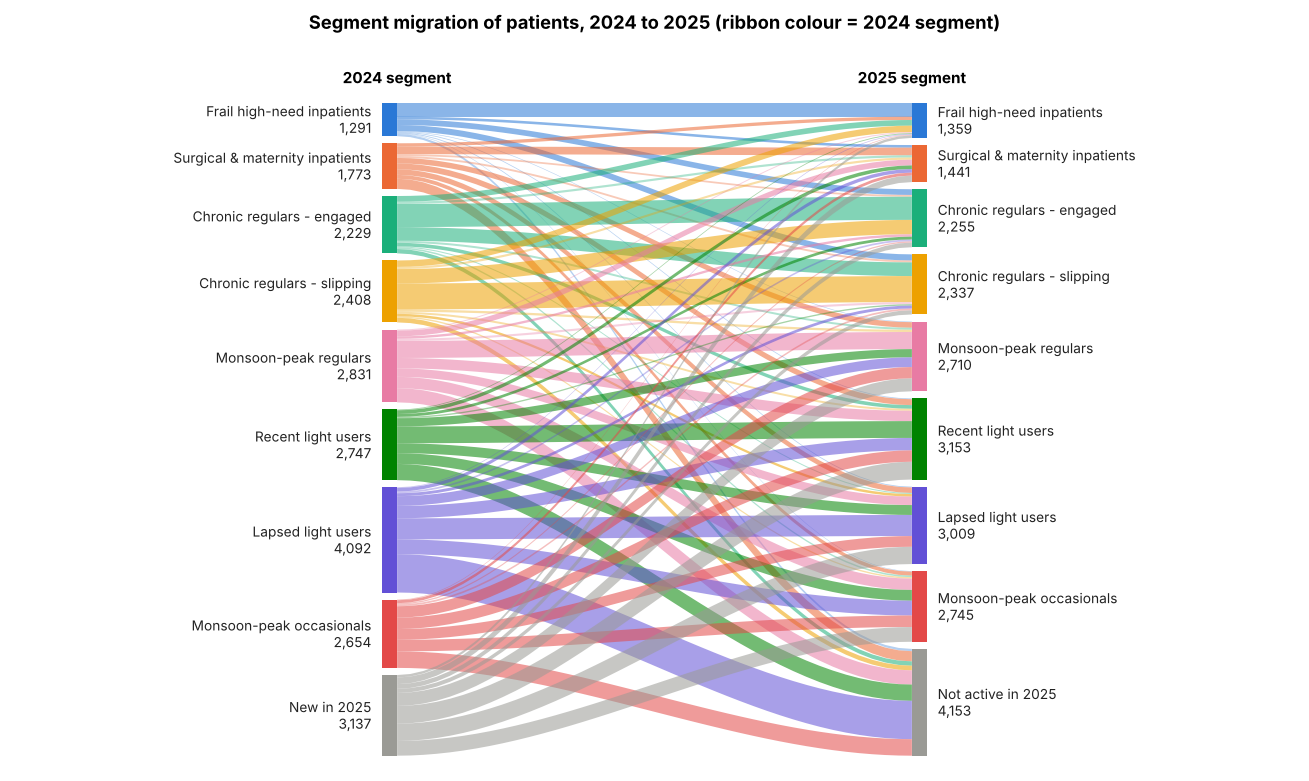

In [25]:
def ribbon_chart(flow, ORDER, COL, path):
    L = list(flow.index); R = list(flow.columns); tot = flow.values.sum(); gap = .012*tot
    fig, ax = plt.subplots(figsize=(12, 7.2)); ax.axis("off"); ax.grid(False)
    ly, ry, y = {}, {}, 0
    for n in L: ly[n] = y; y += flow.loc[n].sum() + gap
    H = y; y = 0
    for n in R: ry[n] = y; y += flow[n].sum() + gap
    H = max(H, y); x0, x1 = .30, .70
    lo = {n: ly[n] for n in L}; ro = {n: ry[n] for n in R}
    t = np.linspace(0, 1, 40); s = 3*t**2 - 2*t**3
    for a in L:
        for b in R:
            v = flow.loc[a, b]
            if v <= 0: continue
            ya, yb = lo[a], ro[b]; lo[a] += v; ro[b] += v
            xs = x0 + (x1-x0)*t
            top = H-(ya+(yb-ya)*s); bot = H-(ya+v+(yb-ya)*s)
            ax.add_patch(Polygon(np.r_[np.c_[xs, top], np.c_[xs, bot][::-1]], closed=True, fc=COL.get(a, GREY), ec="none", alpha=.55 if v/tot > .004 else .35))
    for n in L:
        h = flow.loc[n].sum(); ax.add_patch(plt.Rectangle((x0-.012, H-ly[n]-h), .012, h, fc=COL.get(n, GREY), ec="none"))
        ax.text(x0-.02, H-ly[n]-h/2, f"{n}\n{int(h):,}", ha="right", va="center", fontsize=9, color=INK)
    for n in R:
        h = flow[n].sum(); ax.add_patch(plt.Rectangle((x1, H-ry[n]-h), .012, h, fc=COL.get(n, GREY), ec="none"))
        ax.text(x1+.02, H-ry[n]-h/2, f"{n}\n{int(h):,}", ha="left", va="center", fontsize=9, color=INK)
    ax.text(x0, H*1.03, "2024 segment", ha="center", fontweight="bold"); ax.text(x1, H*1.03, "2025 segment", ha="center", fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(-gap, H*1.08)
    plt.title("Segment migration of patients, 2024 to 2025 (ribbon colour = 2024 segment)", loc="center", fontsize=12, pad=14)
    plt.tight_layout(); plt.savefig(path); plt.show()
ribbon_chart(flow, ORDER, COL, "outputs/segment_migration_chart.png")

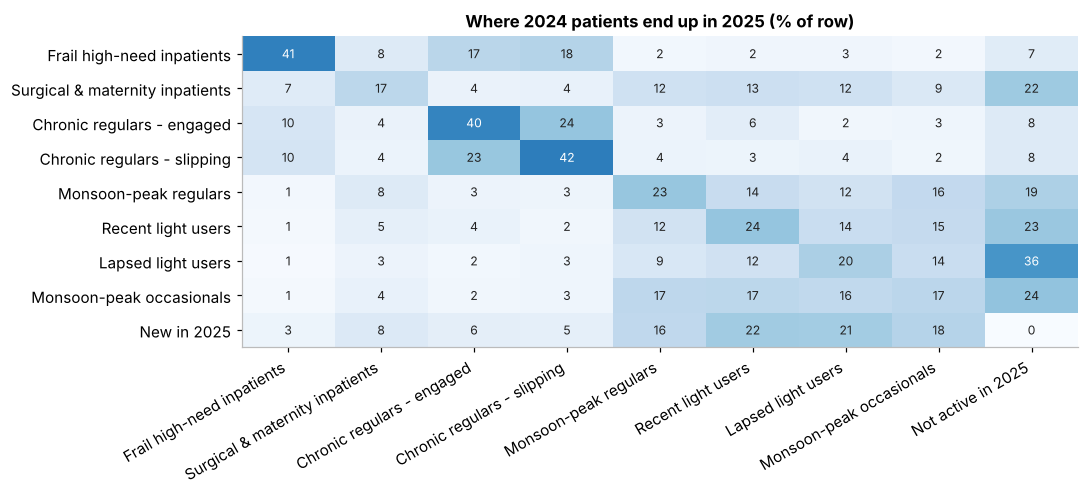

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.6)); fp = flow_pct.copy()
im = ax.imshow(fp.values, cmap="Blues", vmin=0, vmax=60, aspect="auto"); ax.grid(False)
ax.set_xticks(range(fp.shape[1])); ax.set_xticklabels(fp.columns, rotation=30, ha="right"); ax.set_yticks(range(fp.shape[0])); ax.set_yticklabels(fp.index)
for i in range(fp.shape[0]):
    for jx in range(fp.shape[1]): ax.text(jx, i, f"{fp.values[i,jx]:.0f}", ha="center", va="center", fontsize=8, color="white" if fp.values[i,jx] > 35 else INK)
ax.set_title("Where 2024 patients end up in 2025 (% of row)"); plt.tight_layout(); plt.savefig("outputs/segment_migration_heatmap.png"); plt.show()

**How to read stability.** Two separate questions, two different answers.

* **Are the segments themselves stable? Yes.** The noise floor is under 1%, and when k-means is run from scratch on 2024 the same eight profiles come back (every 2024 segment has a close match in 2025; centroid distances are small). The segmentation is not an artefact of the algorithm or the sample.
* **Do individual patients keep their segment? Mostly not, and that is true of every method.** About two thirds of patients seen in both years change segment (k-means 8: 66%, k-means 6: 60%, RFM: 69%). A single year of a patient's behaviour is noisy: someone with 3 visits could easily have had 2 or 5. Clinical-need segments hold best (frail inpatients, chronic regulars: 40-45% stay, and most of the rest move *between* related groups, e.g. engaged <-> slipping chronic, frail -> chronic) while episodic and light segments retain only 20-30% (surgical episodes end; light users drift). About 1 in 5 of the 2024 patients is not seen at all in 2025.

**Consequences for the plan:** (1) re-score patients every quarter instead of freezing a label for a year; (2) trigger programmes on *events* (a discharge, 60 days without a visit, May for monsoon) rather than on a permanent label; (3) the engaged <-> slipping chronic flow is itself a KPI to track (migration chart). RFM is no more stable than k-means, so stability does not change the choice.

## 10. Appendix: check against the simulator's hidden truth (valid only because the data are synthetic)

In [27]:
truth = pd.read_csv("data/_simulation_truth_do_not_use_for_modelling.csv").set_index("patient_id")
t2 = truth.archetype_2025.reindex(f2.index)
print("ARI vs hidden archetype -> k-means:", round(adjusted_rand_score(t2, f2.segment), 3), "| RFM:", round(adjusted_rand_score(t2, f2.rfm), 3))
(pd.crosstab(t2, f2.segment, normalize="index")*100).round(0).astype(int)[ORDER]

ARI vs hidden archetype -> k-means: 0.237 | RFM: 0.168


segment,Frail high-need inpatients,Surgical & maternity inpatients,Chronic regulars - engaged,Chronic regulars - slipping,Monsoon-peak regulars,Recent light users,Lapsed light users,Monsoon-peak occasionals
archetype_2025,,,,,,,,
A_healthy,0,1,0,0,10,30,32,27
B_chronic,6,1,40,42,4,4,2,2
C_episodic,0,17,2,1,21,24,23,12
D_seasonal,0,7,1,1,55,9,4,23
E_surgical,12,41,6,7,11,11,9,4
F_frail,58,6,15,17,1,1,0,1
G_maternal,2,27,9,6,28,16,9,2
H_lapsing,0,4,0,0,10,29,26,31


The hidden archetypes were never used in the analysis. Where a simulated type has a distinctive footprint it is recovered (about 58% of the frail archetype lands in the frail segment, 82% of the chronic archetype in the two chronic segments, 55% of the seasonal archetype in the monsoon-peak regulars, 41% of surgical in the surgical segment). Overall agreement is modest (ARI 0.24 for k-means vs 0.17 for RFM) because several simulated types (healthy, lapsing, episodic) look nearly the same in one year of visits, which is also why light-user labels move so much. This is a sanity check on synthetic data only, not a claim about real accuracy.

## 11. Export

In [28]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
pf = prof[show].reset_index().rename(columns={"segment": "segment"})
assump = pd.DataFrame([
    ("Contribution margin on ex-GST clinic revenue", MARGIN, "assumption"),
    ("Variable cost per occupied bed-day (INR)", BEDDAY, "assumption"),
    ("Share of 30-day readmissions not separately payable", UNREIMB, "assumption"),
    ("Low / base / high effect multiplier", "0.5 / 1.0 / 1.5", "assumption"),
    ("Total beds (140 = 40 + 30 + 45 + 25)", seg.TOTAL_BEDS, "from hospitals.csv"),
    ("Revenue definition", "ex-GST base amount, net of refunds", "cleaning rule"),
    ("Window", "calendar year; segmentation on 2025, stability vs 2024", "design"),
], columns=["item", "value", "type"])
patient_out = f2[["segment", "rfm"]].join(r2[["R","F","M","rfm_score"]]).join(f2[["opd_n","adm_n","lab_n","recency","revenue","growth","monsoon_share","age","chronic_share"]])
with pd.ExcelWriter("outputs/Hospital_Segmentation_Workbook.xlsx", engine="openpyxl") as xw:
    pd.DataFrame({"sheet": ["Segment_profile","Actions_CostBenefit","Assumptions","KPI_separation","Method_comparison","K_selection","Stability","Migration_pct","RFM_profile","Data_quality_log","Patient_segments"],
                  "what it holds": ["Final k-means segments: size, revenue / visit share, LOS, bed-days, occupancy contribution, 30-day readmission",
                                    "One action per segment: cost, low/base/high benefit, measurable target",
                                    "Editable planning assumptions (INR)",
                                    "Eta-squared and Kruskal-Wallis p per KPI",
                                    "RFM vs k-means quality metrics", "Elbow / silhouette / DB / KPI separation for k = 2..10",
                                    "Share of patients changing segment (2024 vs 2025) and noise floor", "2024 -> 2025 transition matrix (% of row)",
                                    "RFM segment profile", "Every cleaning step with rows affected", "Patient-level segment, RFM score and features (2025)"]}).to_excel(xw, "README", index=False)
    pf.to_excel(xw, "Segment_profile", index=False); act.to_excel(xw, "Actions_CostBenefit", index=False); assump.to_excel(xw, "Assumptions", index=False)
    ks.to_excel(xw, "KPI_separation", index=False); cmp.reset_index().to_excel(xw, "Method_comparison", index=False); sw.to_excel(xw, "K_selection", index=False)
    stab.to_excel(xw, "Stability", index=False); ret.reset_index().to_excel(xw, "Stability", index=False, startrow=7)
    flow_pct.round(1).reset_index().to_excel(xw, "Migration_pct", index=False)
    rfm_prof[["patients","share_patients_%","share_revenue_%","visits_per_patient","revenue_per_patient","median_recency_days","avg_LOS_days","occupancy_contrib_pp","readmit_30d_%"]].reset_index().to_excel(xw, "RFM_profile", index=False)
    D["log"].to_excel(xw, "Data_quality_log", index=False); patient_out.reset_index().to_excel(xw, "Patient_segments", index=False)
    for ws in xw.book.worksheets:
        for c in ws[1]: c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="1F2430"); c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.freeze_panes = "B2"
        for i, col in enumerate(ws.columns, 1):
            w = max(len(str(c.value)) if c.value is not None else 0 for c in list(col)[:60]); ws.column_dimensions[get_column_letter(i)].width = min(max(10, w + 2), 70)
        ws.row_dimensions[1].height = 32
prof[show].to_csv("outputs/segment_profile_table.csv"); act.to_csv("outputs/actions_cost_benefit.csv", index=False)
import json
json.dump({"K": K, "network_occupancy_pct": net_occ, "noise_floor": float(np.mean(nf)), "chg_km": float(chg_km), "chg_k6": float(chg_k6), "chg_rfm": float(chg_rfm),
           "ari_rfm_km": float(adjusted_rand_score(f2.rfm, f2.segment)), "n_active_2025": int(len(f2)), "n_both": int(nb)}, open("outputs/summary.json", "w"), indent=1)
print("saved:", sorted(os.listdir("outputs")))

saved: ['Hospital_Segmentation_Workbook.xlsx', 'action_cost_benefit.png', 'actions_cost_benefit.csv', 'segment_migration_chart.png', 'segment_migration_heatmap.png', 'segment_profile_chart.png', 'segment_profile_table.csv', 'summary.json']
